In [8]:
import cv2
from bs4 import BeautifulSoup
from IPython.display import Image
import matplotlib.pyplot as plt
import PIL.Image
from pathlib import Path
from natsort import natsorted
import json
from collections import defaultdict

from src.xml_image_coordinates import (
    get_single_xml_path,
    get_single_img_path,
    get_left_right_xml_tables,
    get_cell_coords
)

In [9]:
events_json = (
    "outputs/json/all_migration_events_parish_splits/"
    "395_migration_events.jsonl"
)

with open(events_json, "r") as fp:
    lines = tuple(
        json.loads(json_line)
        for json_line in fp
    )
    xml_path = get_single_xml_path(Path(lines[0]["file_path"]).stem, Path("data/xml"))
    img_path = get_single_img_path(Path(lines[0]["file_path"]).stem, Path("data/xml"))

with open(xml_path, "r") as fp:
    xml = BeautifulSoup(fp.read(), features="xml")

['Sulkava', '7', '1', 'Drengen Anders Olofsson Kumbulain bel. 29/9 1853', 'Idensalmi', '1', '-']


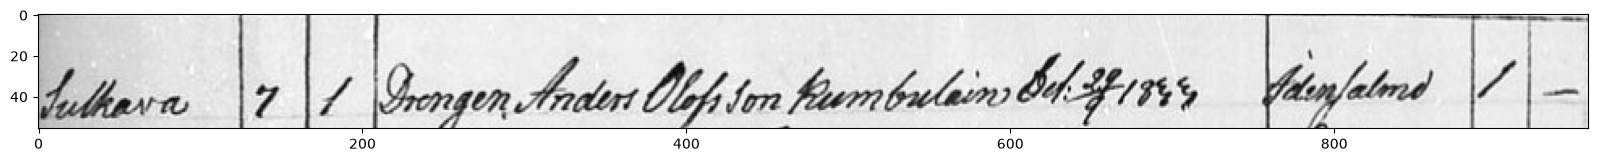

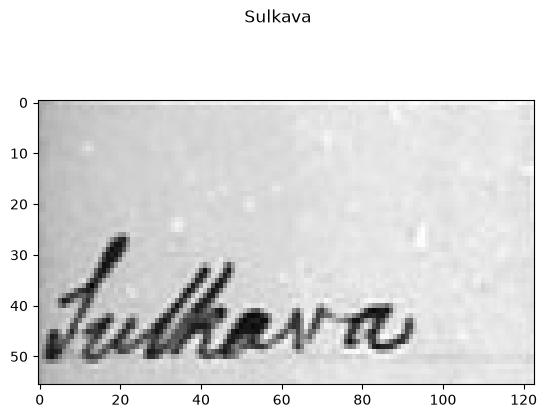

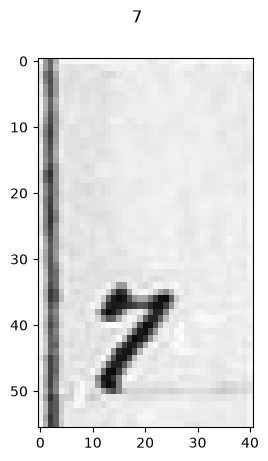

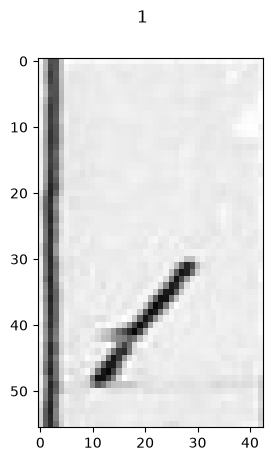

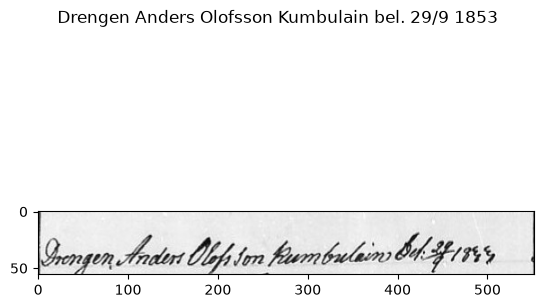

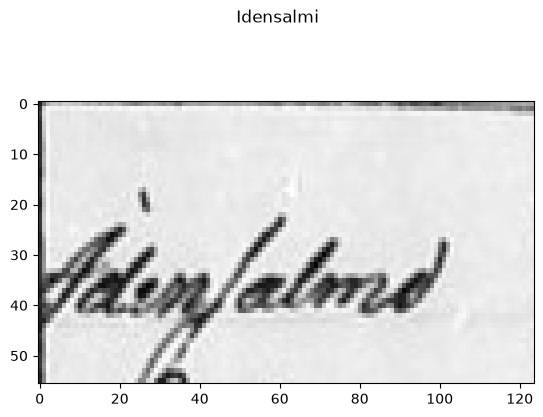

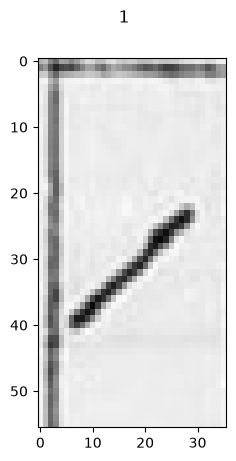

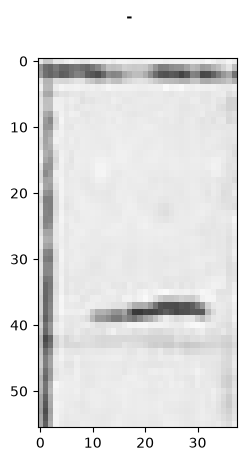

In [10]:
left_table, right_table = get_left_right_xml_tables(xml)
left_table_rows = defaultdict(list)
for cell in left_table.find_all("TableCell"):
    left_table_rows[int(cell["row"])].append(cell)

row = 0
row_text = lines[row]["row_data"]
print(row_text)

img = cv2.imread(img_path, cv2.IMREAD_COLOR_RGB)
x0, y0 = get_cell_coords(left_table_rows[row][0])[0]
x1, y1 = get_cell_coords(left_table_rows[row][-1])[2]
img_cropped = img[y0:y1, x0:x1]
aspect_ratio = (img.shape[1] / img.shape[0])
fig, axs = plt.subplots(1, 1, figsize=(20, 10))
plt.imshow(img_cropped, aspect=aspect_ratio)

for i, cell in enumerate(left_table_rows[row]):
    current_cell_coords = get_cell_coords(cell)
    x0, y0 = current_cell_coords[0]
    x1, y1 = current_cell_coords[2]
    img_cropped = img[y0:y1, x0:x1]
    aspect_ratio = (img.shape[1] / img.shape[0])
    
    fig, axs = plt.subplots(1, 1)#, figsize=(20, 10))
    axs = plt.imshow(img_cropped, aspect=aspect_ratio)
    plt.suptitle(row_text[i])